# Automatische Müllsortierung mit ResNet18
**Deep Learning für Computer Vision – Notebook 06**

Datensatz: https://www.kaggle.com/datasets/mostafaabla/garbage-classification

ResNet18: https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html 

Wir vergleichen drei Wege, Müllbilder in zwölf Klassen einzuteilen:

1. **Ohne Vortraining:** Eine zufällig initialisierte ResNet18 lernt alle Gewichte neu.
2. **Mit Vortraining:** ImageNet-Gewichte bleiben eingefroren. Nur der neue Kopf lernt.
3. **Mit Vortraining:** Der neue Kopf und der letzte ResNet-Block lernen gemeinsam.

Jede Variante erhält dieselben Trainings-, Validierungs- und Testbilder und jeweils **30
Trainingsepochen**. Variante 2 und 3 starten unabhängig voneinander mit ImageNet-Gewichten. Für jede Variante zeigen wir die **Korrektklassifikationsrate** und eine
**Confusion Matrix**. Außerdem prüfen wir: Wird Papier/Pappe häufiger verwechselt als Glas/Kunststoff?

Die Kennzahlen entstehen beim Ausführen der Zellen. Eine höhere Genauigkeit durch Vortraining
ist eine Erwartung, kein vorgegebenes Ergebnis. Alle Zellen von oben nach unten ausführen.
Der erste Download benötigt Internet; das Training läuft mit GPU schneller.

# Bibliotheken und Einstellungen
`BILDER_PRO_KLASSE` begrenzt den Datensatz für die Vorlesung auf höchstens so viele Bilder je Klasse.

Davon verwenden wir 70 % zum Trainieren, 15 % zur Validierung und 15 % zum Testen.
Für einen ausführlicheren Versuch kann die Grenze erhöht werden.

Wir verzichten auf Duplikatprüfung, automatische Ordnersuche und das Speichern von Modellzuständen.
Die Testwerte beschreiben die ausgewählten Datensatzbilder; ähnliche Bilder können in verschiedenen
Splits vorkommen. Eine reale Sortieranlage müsste separat mit eigenen Aufnahmen geprüft werden.

In [1]:
# %pip install torch torchvision kagglehub numpy matplotlib scikit-learn

from pathlib import Path
import time

import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
BILDER_PRO_KLASSE = 600
EPOCHEN = 50
BATCH_SIZE = 32

np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Gerät:", DEVICE)

Gerät: cuda


# Müllbilder herunterladen und laden
`kagglehub` lädt [Garbage Classification](https://www.kaggle.com/datasets/mostafaabla/garbage-classification)
herunter. Der Unterordner `garbage_classification` enthält einen Ordner je Klasse.
`ImageFolder` verwendet die Ordnernamen als Labels.

Alle drei Modelle erhalten dieselbe Vorverarbeitung: auf 256 Pixel skalieren, mittig auf
224 × 224 Pixel zuschneiden und mit den ImageNet-Werten normalisieren.
Wir verwenden hier bewusst keine zusätzliche zufällige Bildaugmentation.

In [2]:
pfad = Path(kagglehub.dataset_download("mostafaabla/garbage-classification"))
gewichte = models.ResNet18_Weights.IMAGENET1K_V1
bilder = datasets.ImageFolder(pfad / "garbage_classification", transform=gewichte.transforms())
klassen = bilder.classes
labels = np.array(bilder.targets)

print("Bilder insgesamt:", len(bilder))
print("Klassen:", klassen)
print("Labels Beispiele:", labels[:5], labels[-5:])

Bilder insgesamt: 15515
Klassen: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Labels Beispiele: [0 0 0 0 0] [11 11 11 11 11]


In [3]:
bilder

Dataset ImageFolder
    Number of datapoints: 15515
    Root location: /home/juebrauer/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1/garbage_classification
    StandardTransform
Transform: ImageClassification(
               crop_size=[224]
               resize_size=[256]
               mean=[0.485, 0.456, 0.406]
               std=[0.229, 0.224, 0.225]
               interpolation=InterpolationMode.BILINEAR
           )

In [4]:
gewichte

ResNet18_Weights.IMAGENET1K_V1

# Trainings-, Validierungs- und Testdaten aufteilen
Zuerst wählen wir zufällig höchstens BILDER_PRO_KLASSE Bilder je Klasse aus.
`stratify` sorgt dafür, dass die Klassenanteile beim Aufteilen ungefähr erhalten bleiben.
Die Aufteilung wird einmal erstellt und für alle Modelle wiederverwendet.
Der Testdatensatz wird ausschließlich für die abschließenden Berichte genutzt.

In [5]:
auswahl = []
for klasse in range(len(klassen)):
    indizes = np.where(labels == klasse)[0]
    np.random.shuffle(indizes)
    auswahl.extend(indizes[:BILDER_PRO_KLASSE])

train_idx, rest_idx = train_test_split(
    auswahl, test_size=0.30, random_state=SEED, stratify=labels[auswahl]
)
val_idx, test_idx = train_test_split(
    rest_idx, test_size=0.50, random_state=SEED, stratify=labels[rest_idx]
)

train_loader = DataLoader(Subset(bilder, train_idx), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(Subset(bilder, val_idx), batch_size=BATCH_SIZE)
test_loader = DataLoader(Subset(bilder, test_idx), batch_size=BATCH_SIZE)

print(f"Training: {len(train_idx)} | Validierung: {len(val_idx)} | Test: {len(test_idx)}")

Training: 5040 | Validierung: 1080 | Test: 1080


In [6]:
len(auswahl)

7200

In [7]:
12*BILDER_PRO_KLASSE

7200

In [8]:
type(auswahl)

list

In [9]:
auswahl[:5]

[np.int64(848), np.int64(333), np.int64(280), np.int64(30), np.int64(168)]

# Beispiele aus dem Training ansehen
Wir machen die Normalisierung für die Darstellung rückgängig.
Die Bilder zeigen genau den Ausschnitt, den das Modell erhält.

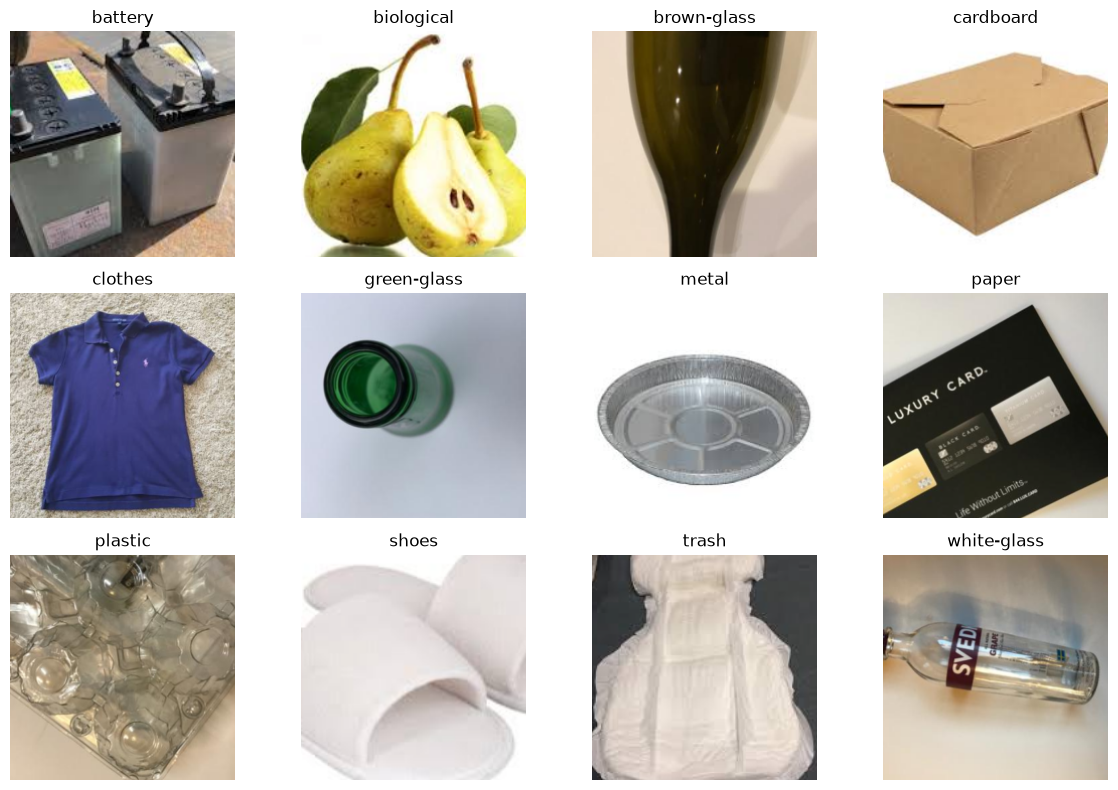

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for klasse, ax in enumerate(axes.flat):
    index = next(i for i in train_idx if labels[i] == klasse)
    bild, label = bilder[index]
    bild = bild * torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    bild = bild + torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    ax.imshow(bild.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(klassen[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

# Eine Funktion zum Bewerten
Die Funktion gibt die wahren Klassen und die vorhergesagten Klassen zurück.
`eval()` aktiviert den Evaluationsmodus; `no_grad()` schaltet die Gradientenberechnung ab.
Die größte Ausgabe des Modells bestimmt die vorhergesagte Klasse.

In [11]:
def vorhersagen(modell, loader):
    modell.eval()
    wahr, vorhergesagt = [], []
    with torch.no_grad():
        for x, y in loader:
            ausgabe = modell(x.to(DEVICE))
            wahr.extend(y.tolist())
            vorhergesagt.extend(ausgabe.argmax(dim=1).cpu().tolist())
    return wahr, vorhergesagt

# Eine Funktion zum Trainieren
Die zentrale Schleife besteht aus vier Schritten: Vorhersage, Loss, Backpropagation und Gewichtsupdate.
`CrossEntropyLoss` erwartet die direkten Modellausgaben (Logits); ein Softmax-Layer ist nicht nötig.
Nach jeder Epoche messen wir die Validierungs-Accuracy.

`modus` legt fest, welche Teile im Trainingsmodus sind:

- `alle`: die gesamte ResNet18.
- `kopf`: nur der neue Kopf `fc`.
- `finetuning`: Kopf und letzter Block `layer4`.

Das Einfrieren der Gewichte geschieht später direkt bei den Modellen mit `requires_grad`.
Der Evaluationsmodus der eingefrorenen Blöcke verhindert zusätzlich, dass sich deren
BatchNorm-Statistiken verändern. Wir bewerten immer den **letzten** Zustand eines Versuchs;
die Validierung dient hier nur der Beobachtung, nicht der Auswahl eines Checkpoints.

In [12]:
loss_funktion = nn.CrossEntropyLoss()

def trainieren(modell, optimizer, epochen, modus):
    verlauf = []
    start = time.perf_counter()
    for epoche in range(epochen):
        if modus == "alle":
            modell.train()
        else:
            modell.eval()
            modell.fc.train()
            if modus == "finetuning":
                modell.layer4.train()

        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            ausgabe = modell(x)
            loss = loss_funktion(ausgabe, y)
            loss.backward()
            optimizer.step()

        wahr, vorhergesagt = vorhersagen(modell, val_loader)
        accuracy = accuracy_score(wahr, vorhergesagt)
        verlauf.append(accuracy)
        print(f"Epoche {epoche + 1}/{epochen}: Validierungs-Accuracy = {accuracy:.1%}", flush=True)

    sekunden = time.perf_counter() - start
    return verlauf, sekunden

# Eine Funktion für den Testbericht
Die Korrektklassifikationsrate ist der Anteil richtig vorhergesagter Testbilder.
Bei der Confusion Matrix stehen die **wahren Klassen in den Zeilen** und die **Vorhersagen in den Spalten**.
Wir zeigen Prozentwerte je Zeile: Die Diagonale enthält die Trefferquote der jeweiligen Klasse.
Die zugrunde liegenden absoluten Anzahlen behalten wir für die spätere Analyse.

In [13]:
ergebnisse = {}

def testbericht(name, modell):
    wahr, vorhergesagt = vorhersagen(modell, test_loader)
    accuracy = accuracy_score(wahr, vorhergesagt)
    matrix = confusion_matrix(wahr, vorhergesagt, labels=range(len(klassen)))
    anteile = matrix / matrix.sum(axis=1, keepdims=True)
    ergebnisse[name] = {"accuracy": accuracy, "matrix": matrix, "anteile": anteile}
    print(f"{name}: Test-Korrektklassifikationsrate = {accuracy:.2%}")

    fig, ax = plt.subplots(figsize=(11, 9))
    anzeige = ConfusionMatrixDisplay(anteile, display_labels=klassen)
    anzeige.plot(ax=ax, cmap="Blues", values_format=".0%", xticks_rotation=60, colorbar=False)
    ax.set_xlabel("Vorhergesagte Klasse")
    ax.set_ylabel("Wahre Klasse")
    ax.set_title(f"{name} – Test-Accuracy {accuracy:.2%}")
    plt.tight_layout()
    plt.show()

# Variante 1: Ohne Vortraining
`weights=None` erzeugt eine ResNet18 mit zufälligen Gewichten.
Wir ersetzen den ImageNet-Kopf durch einen Kopf mit zwölf Ausgaben und trainieren alle Parameter.
Vor jedem neuen Kopf setzen wir denselben Seed: Alle Varianten starten dadurch mit denselben Kopfgewichten.

Epoche 1/50: Validierungs-Accuracy = 43.9%
Epoche 2/50: Validierungs-Accuracy = 48.2%
Epoche 3/50: Validierungs-Accuracy = 45.7%
Epoche 4/50: Validierungs-Accuracy = 55.3%
Epoche 5/50: Validierungs-Accuracy = 57.6%
Epoche 6/50: Validierungs-Accuracy = 52.4%
Epoche 7/50: Validierungs-Accuracy = 58.0%
Epoche 8/50: Validierungs-Accuracy = 57.1%
Epoche 9/50: Validierungs-Accuracy = 60.1%
Epoche 10/50: Validierungs-Accuracy = 58.9%
Epoche 11/50: Validierungs-Accuracy = 58.5%
Epoche 12/50: Validierungs-Accuracy = 58.4%
Epoche 13/50: Validierungs-Accuracy = 60.6%
Epoche 14/50: Validierungs-Accuracy = 62.2%
Epoche 15/50: Validierungs-Accuracy = 65.6%
Epoche 16/50: Validierungs-Accuracy = 61.5%
Epoche 17/50: Validierungs-Accuracy = 64.1%
Epoche 18/50: Validierungs-Accuracy = 67.2%
Epoche 19/50: Validierungs-Accuracy = 68.6%
Epoche 20/50: Validierungs-Accuracy = 66.2%
Epoche 21/50: Validierungs-Accuracy = 68.5%
Epoche 22/50: Validierungs-Accuracy = 68.6%
Epoche 23/50: Validierungs-Accuracy = 68.

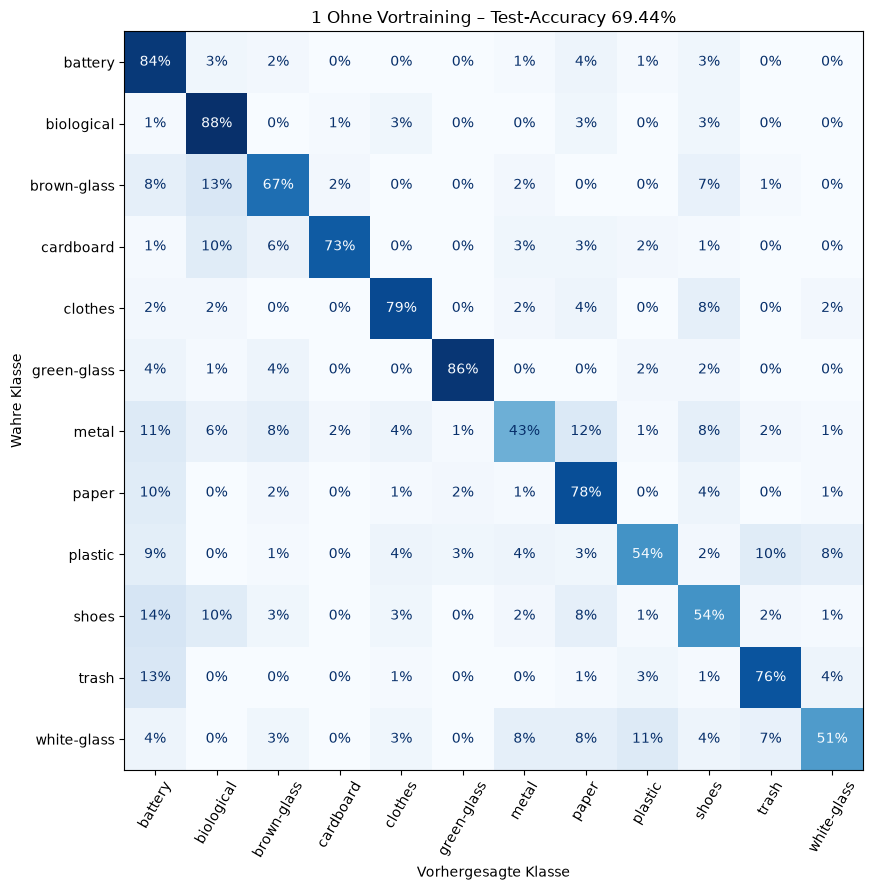

In [14]:
modell_1 = models.resnet18(weights=None)
torch.manual_seed(SEED)
modell_1.fc = nn.Linear(modell_1.fc.in_features, len(klassen))
modell_1 = modell_1.to(DEVICE)

optimizer = torch.optim.Adam(modell_1.parameters(), lr=1e-3)
verlauf_1, zeit_1 = trainieren(modell_1, optimizer, EPOCHEN, modus="alle")
testbericht("1 Ohne Vortraining", modell_1)
modell_1 = modell_1.cpu()  # GPU-Speicher für den nächsten Versuch freigeben

# Variante 2: Mit Vortraining, nur den Kopf neu lernen
Wir laden ImageNet-Gewichte und frieren alle bestehenden Parameter ein.
Der anschließend eingesetzte neue Kopf ist standardmäßig trainierbar.
Nur dieser Kopf lernt für 30 Epochen; die Bildmerkmale bleiben unverändert.

Epoche 1/50: Validierungs-Accuracy = 86.1%
Epoche 2/50: Validierungs-Accuracy = 88.1%
Epoche 3/50: Validierungs-Accuracy = 88.9%
Epoche 4/50: Validierungs-Accuracy = 89.3%
Epoche 5/50: Validierungs-Accuracy = 89.4%
Epoche 6/50: Validierungs-Accuracy = 89.9%
Epoche 7/50: Validierungs-Accuracy = 89.4%
Epoche 8/50: Validierungs-Accuracy = 89.8%
Epoche 9/50: Validierungs-Accuracy = 89.7%
Epoche 10/50: Validierungs-Accuracy = 90.1%
Epoche 11/50: Validierungs-Accuracy = 90.5%
Epoche 12/50: Validierungs-Accuracy = 90.2%
Epoche 13/50: Validierungs-Accuracy = 89.8%
Epoche 14/50: Validierungs-Accuracy = 90.0%
Epoche 15/50: Validierungs-Accuracy = 89.6%
Epoche 16/50: Validierungs-Accuracy = 89.7%
Epoche 17/50: Validierungs-Accuracy = 89.8%
Epoche 18/50: Validierungs-Accuracy = 89.4%
Epoche 19/50: Validierungs-Accuracy = 90.3%
Epoche 20/50: Validierungs-Accuracy = 89.9%
Epoche 21/50: Validierungs-Accuracy = 89.4%
Epoche 22/50: Validierungs-Accuracy = 89.2%
Epoche 23/50: Validierungs-Accuracy = 90.

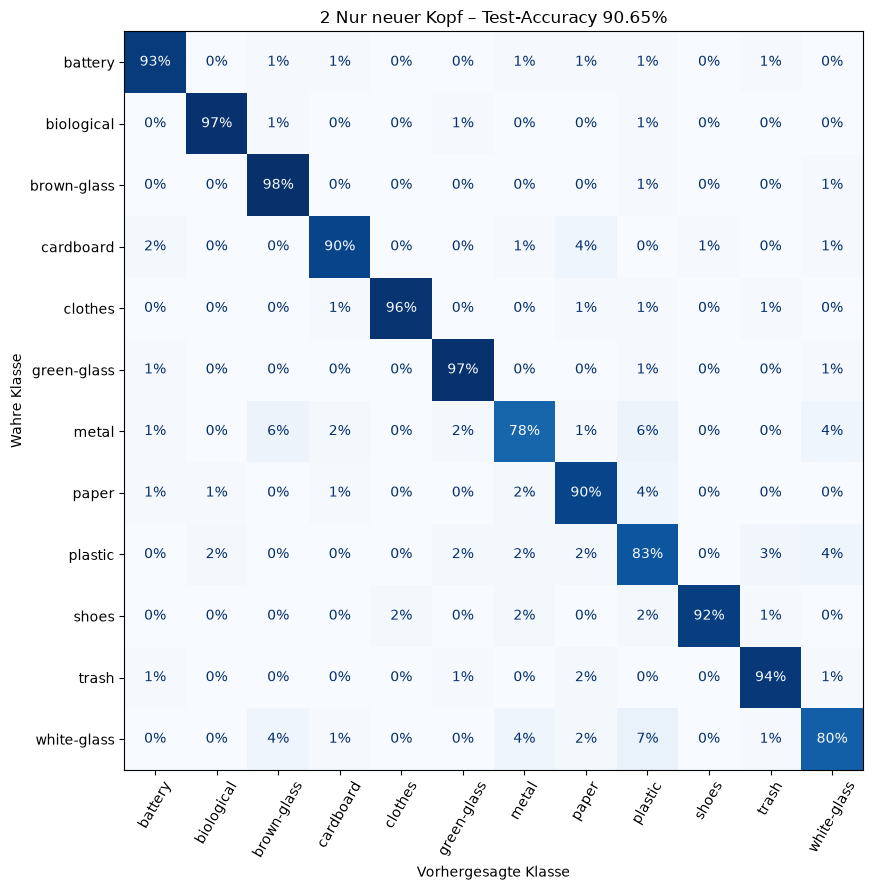

In [15]:
modell_2 = models.resnet18(weights=gewichte)
for parameter in modell_2.parameters():
    parameter.requires_grad = False

torch.manual_seed(SEED)
modell_2.fc = nn.Linear(modell_2.fc.in_features, len(klassen))
modell_2 = modell_2.to(DEVICE)

optimizer = torch.optim.Adam(modell_2.fc.parameters(), lr=1e-3)
verlauf_2, zeit_2 = trainieren(modell_2, optimizer, EPOCHEN, modus="kopf")
testbericht("2 Nur neuer Kopf", modell_2)
modell_2 = modell_2.cpu()

# Variante 3: Mit Vortraining, Kopf und letzten Block lernen
Wir laden eine neue ResNet18 mit ImageNet-Gewichten und setzen einen neuen Kopf ein.
Zusätzlich geben wir die Parameter des letzten Blocks `layer4` frei.
Kopf und letzter Block lernen **von Anfang an gemeinsam für 30 Epochen**.
Die früheren Blöcke bleiben eingefroren.

Für `layer4` verwenden wir eine kleinere Lernrate als für den neuen Kopf,
damit sich die vorhandenen Bildmerkmale behutsam ändern.

Epoche 1/50: Validierungs-Accuracy = 79.2%
Epoche 2/50: Validierungs-Accuracy = 85.5%
Epoche 3/50: Validierungs-Accuracy = 88.5%
Epoche 4/50: Validierungs-Accuracy = 90.0%
Epoche 5/50: Validierungs-Accuracy = 91.1%
Epoche 6/50: Validierungs-Accuracy = 91.1%
Epoche 7/50: Validierungs-Accuracy = 92.1%
Epoche 8/50: Validierungs-Accuracy = 92.3%
Epoche 9/50: Validierungs-Accuracy = 92.5%
Epoche 10/50: Validierungs-Accuracy = 92.8%
Epoche 11/50: Validierungs-Accuracy = 93.5%
Epoche 12/50: Validierungs-Accuracy = 93.4%
Epoche 13/50: Validierungs-Accuracy = 93.8%
Epoche 14/50: Validierungs-Accuracy = 93.7%
Epoche 15/50: Validierungs-Accuracy = 94.0%
Epoche 16/50: Validierungs-Accuracy = 93.8%
Epoche 17/50: Validierungs-Accuracy = 93.5%
Epoche 18/50: Validierungs-Accuracy = 94.1%
Epoche 19/50: Validierungs-Accuracy = 94.3%
Epoche 20/50: Validierungs-Accuracy = 94.5%
Epoche 21/50: Validierungs-Accuracy = 94.4%
Epoche 22/50: Validierungs-Accuracy = 94.0%
Epoche 23/50: Validierungs-Accuracy = 94.

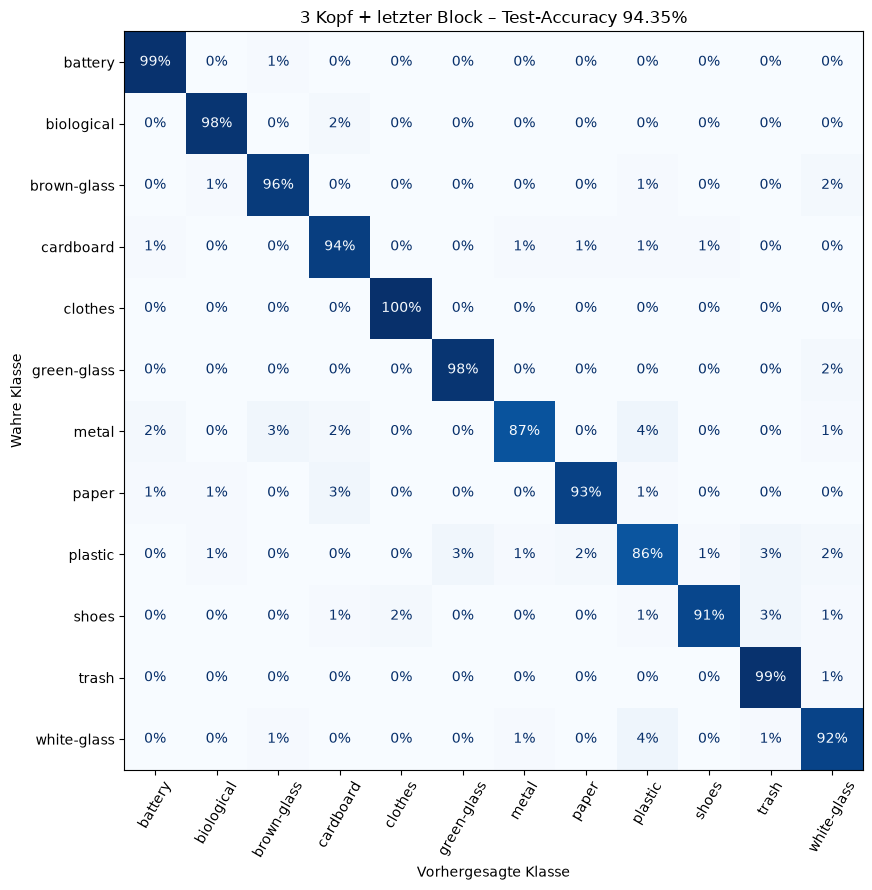

In [16]:
modell_3 = models.resnet18(weights=gewichte)
for parameter in modell_3.parameters():
    parameter.requires_grad = False

torch.manual_seed(SEED)
modell_3.fc = nn.Linear(modell_3.fc.in_features, len(klassen))
for parameter in modell_3.layer4.parameters():
    parameter.requires_grad = True
modell_3 = modell_3.to(DEVICE)

optimizer = torch.optim.Adam([
    {"params": modell_3.layer4.parameters(), "lr": 1e-5},
    {"params": modell_3.fc.parameters(), "lr": 1e-4},
])
verlauf_3, zeit_3 = trainieren(modell_3, optimizer, EPOCHEN, modus="finetuning")
testbericht("3 Kopf + letzter Block", modell_3)
modell_3 = modell_3.cpu()

# Ergebnisse und Lernkurven vergleichen
Die Zeiten umfassen Training und Validierung; Download und abschließende Testberichte sind nicht enthalten.
Gleiche Epochen bedeuten gleiche Datenkontakte, aber keine gleiche Laufzeit.
Das kurze Training ohne Vorwissen ist eine Baseline bei begrenztem Budget, keine ausoptimierte Referenz.
Beim erneuten Ausführen sind kleine Abweichungen durch Zufallsreihenfolge und Hardware möglich.

1 Ohne Vortraining: Accuracy 69.44% | Zeit 8.6 min
2 Nur neuer Kopf: Accuracy 90.65% | Zeit 8.3 min
3 Kopf + letzter Block: Accuracy 94.35% | Zeit 8.4 min


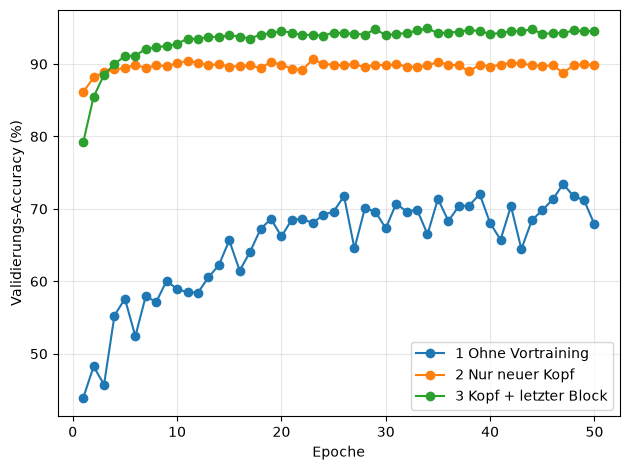

In [17]:
for (name, ergebnis), zeit in zip(ergebnisse.items(), [zeit_1, zeit_2, zeit_3]):
    print(f"{name}: Accuracy {ergebnis['accuracy']:.2%} | Zeit {zeit / 60:.1f} min")

for name, verlauf in zip(ergebnisse, [verlauf_1, verlauf_2, verlauf_3]):
    plt.plot(range(1, EPOCHEN + 1), np.array(verlauf) * 100, marker="o", label=name)
plt.xlabel("Epoche")
plt.ylabel("Validierungs-Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()